In [40]:
import csv
import numpy as np

In [41]:
# known world coordinates of the calibration pattern points, remove headings
pointsWorld = list(csv.reader(open('pointsCamera.csv', 'r')))
pointsWorld = pointsWorld[1:]  # Remove the first row (headings)
# known image coordinates of the calibration pattern points, remove headings
pointsImage = list(csv.reader(open('points.csv', 'r')))
pointsImage = pointsImage[1:]  # Remove the first row (headings)

In [42]:
pointsWorld

[['0', '0', '-180'],
 ['73.1', '22.9', '-91.9'],
 ['52.1', '0', '-108.3'],
 ['22.6', '14.3', '-51'],
 ['59.6', '0', '-44.4'],
 ['17.7', '5.5', '-25.3'],
 ['12.5', '0', '-19.2'],
 ['64.4', '0', '-19'],
 ['51.7', '1.8', '-5.9'],
 ['0', '0', '0'],
 ['0', '80', '0'],
 ['0', '-2.7', '0']]

In [43]:
pointsImage

[['1010', '1260'],
 ['2150', '1337'],
 ['1713', '1625'],
 ['1131', '1819'],
 ['2000', '2228'],
 ['871', '2439'],
 ['722', '2693'],
 ['2266', '2671'],
 ['1945', '2948'],
 ['130', '3192'],
 ['2958', '3131'],
 ['146', '3258']]

In [44]:
n = len(pointsImage)
# M is a n times 12 matrix
# each row is [-Xi, -Yi, -Zi, -1, 0, 0, 0, 0, xi*Xi, xi*Yi, xi*Zi, xi] or [0, 0, 0, 0, -Xi, -Yi, -Zi, -1, yi*Xi, yi*Yi, yi*Zi, yi]
M = []
for i in range(n):
    row1 = [-float(pointsWorld[i][0]),
            -float(pointsWorld[i][1]),
            -float(pointsWorld[i][2]),
            -1, 0, 0, 0, 0,
            float(pointsImage[i][0]) * float(pointsWorld[i][0]),
            float(pointsImage[i][0]) * float(pointsWorld[i][1]),
            float(pointsImage[i][0]) * float(pointsWorld[i][2]),
            float(pointsImage[i][0])]
    row2 = [0, 0, 0, 0,
            -float(pointsWorld[i][0]),
            -float(pointsWorld[i][1]),
            -float(pointsWorld[i][2]),
            -1,
            float(pointsImage[i][1]) * float(pointsWorld[i][0]),
            float(pointsImage[i][1]) * float(pointsWorld[i][1]),
            float(pointsImage[i][1]) * float(pointsWorld[i][2]),
            float(pointsImage[i][1])]
    M.append(row1)
    M.append(row2)

In [45]:
# Now we can use SVD to solve for the camera matrix P
M = np.array(M)

In [46]:
# Perform SVD
U, S, Vt = np.linalg.svd(M)
# The solution is the last column of V (or the last row of Vt)
P = Vt[-1].reshape(3, 4)

In [47]:
P # This is the camera projection matrix that maps 3D world coordinates to 2D image coordinates.

array([[ 1.34589709e-02, -1.16601262e-02, -5.82697055e-03,
         2.59943535e-02],
       [ 2.37799650e-03, -2.44762129e-02, -1.80547542e-03,
         9.99182237e-01],
       [ 9.44957246e-07, -7.67270314e-06, -4.14850421e-06,
         3.08291253e-04]])

In [48]:
# Now we can decompose the camera matrix P into intrinsic and extrinsic parameters.
H = P[:, :3]  # The first three columns of P
h = P[:, 3]   # The last column of P
H_inv = np.linalg.inv(H)
R_inv, K_inv = np.linalg.qr(H_inv)  # QR decomposition to get R and K
K = np.linalg.inv(K_inv)
R = np.linalg.inv(R_inv)
# Normalize K so that K[2, 2] = 1
K = K / K[2, 2]

In [49]:
K

array([[ 1.36540282e+03, -4.14472979e+01,  1.64155465e+03],
       [-0.00000000e+00, -1.14586141e+03,  2.56628693e+03],
       [ 0.00000000e+00,  0.00000000e+00,  1.00000000e+00]])

In [50]:
R

array([[-0.99417173, -0.09250513, -0.05536583],
       [-0.00467862, -0.47605497,  0.87940308],
       [-0.10770647,  0.87453671,  0.4728476 ]])

In [51]:
# we can also compute the translation vector X_0
X_0 =  -H_inv @ h

In [52]:
X_0

array([36.77901343, 44.34625014,  0.67258834])

In [53]:
# Parameters of the camera are now:
print ('Intrinsic parameters (K):')
print (K)

print ('Extrinsic parameters (R):')
print (R)

print ('Translation vector (X_0):')
print (X_0)


Intrinsic parameters (K):
[[ 1.36540282e+03 -4.14472979e+01  1.64155465e+03]
 [-0.00000000e+00 -1.14586141e+03  2.56628693e+03]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00]]
Extrinsic parameters (R):
[[-0.99417173 -0.09250513 -0.05536583]
 [-0.00467862 -0.47605497  0.87940308]
 [-0.10770647  0.87453671  0.4728476 ]]
Translation vector (X_0):
[36.77901343 44.34625014  0.67258834]


Projected image points (x, y):
[[1018.79301152 1255.10918112]
 [2193.00793189 1335.42287049]
 [1683.51097127 1634.35568581]
 [1067.44229847 1842.3913749 ]
 [1980.42640637 2224.97155129]
 [ 896.16514608 2455.89294387]
 [ 765.74328665 2660.56372662]
 [2240.03576487 2648.91472844]
 [1998.891671   2959.99906444]
 [  84.31751873 3241.0333626 ]
 [2968.05743276 3138.58048198]
 [ 174.69718838 3237.82237348]]
Mean reprojection error: 38.36 pixels
Maximum reprojection error: 67.73 pixels


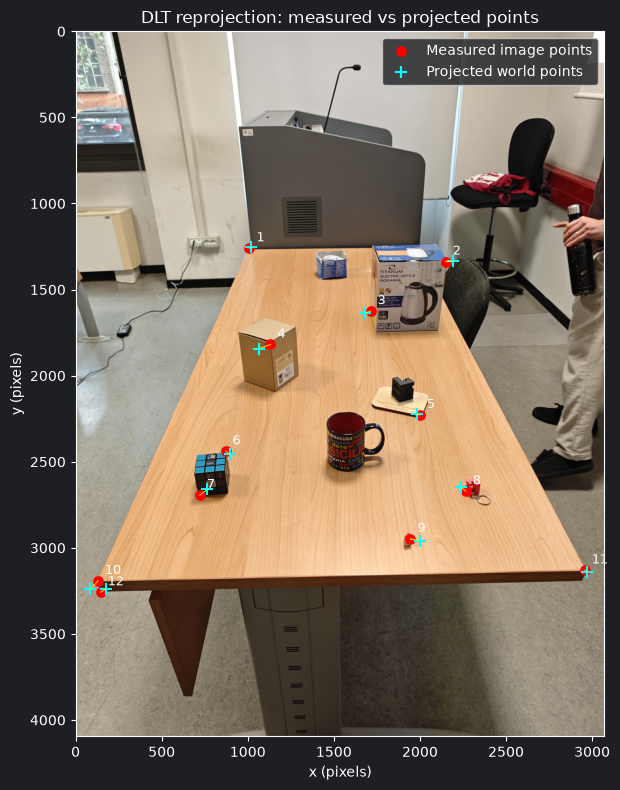

In [54]:
# Now we can use the camera matrix P to project 3D world points to 2D image points and compare with the known image points.
# Calculate the projected image points and display the original image with both sets of points.
import matplotlib.pyplot as plt

world_points = np.asarray(pointsWorld, dtype=float)
image_points = np.asarray(pointsImage, dtype=float)
world_points_h = np.column_stack((world_points, np.ones(len(world_points))))

# Convert homogeneous image coordinates to pixel coordinates.
projected_points_h = (P @ world_points_h.T).T
projected_points = projected_points_h[:, :2] / projected_points_h[:, 2, np.newaxis]

reprojection_errors = np.linalg.norm(projected_points - image_points, axis=1)
print("Projected image points (x, y):")
print(projected_points)
print(f"Mean reprojection error: {reprojection_errors.mean():.2f} pixels")
print(f"Maximum reprojection error: {reprojection_errors.max():.2f} pixels")

image = plt.imread('image.jpg')
fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(image)
ax.scatter(image_points[:, 0], image_points[:, 1], c='red', marker='o', s=45,
           label='Measured image points')
ax.scatter(projected_points[:, 0], projected_points[:, 1], c='cyan', marker='+', s=80,
           label='Projected world points')

for i, (measured, projected) in enumerate(zip(image_points, projected_points)):
    ax.plot([measured[0], projected[0]], [measured[1], projected[1]],
            color='yellow', linewidth=0.8, alpha=0.8)
    ax.annotate(str(i + 1), measured, xytext=(5, 5), textcoords='offset points',
                color='white', fontsize=9)

ax.set_title('DLT reprojection: measured vs projected points')
ax.set_xlabel('x (pixels)')
ax.set_ylabel('y (pixels)')
ax.legend()
ax.set_xlim(0, image.shape[1])
ax.set_ylim(image.shape[0], 0)
plt.tight_layout()
plt.show()
 